# Вопрос 20. Марковский процесс принятия решения — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/20-markov-decision-process/examples.ipynb`; в git
идёт **этот** файл, ноутбук — производный артефакт.

Правила: каждый пример отвечает на вопрос из `theory.md`; seed задан явно;
число, попавшее в `theory.md` или `slides.md`, печатается здесь.

Все данные задачи «садовника» — из [60] (гл. 19, печ. 738): матрицы P¹, P²,
R¹, R² сверены с изображением страницы (текстовый слой местами битый).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20261105
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
# Expected values are from [60], ch. 19 (verified against pp. 739-752).
GOLDEN = {
    "v1": np.array([5.3, 3.0, -1.0]),        # one-step rewards, no fertilizer
    "v2": np.array([4.7, 3.1, 0.4]),         # one-step rewards, with fertilizer
    "f1": np.array([10.7355, 7.9225, 4.22225]),  # N = 3, optimum from stage 1
    "f2": np.array([8.19, 5.61, 2.125]),         # N = 3, optimum from stage 2
    "gain2": 2.256,                          # average annual gain of "always fertilize"
    "mu2": np.array([6.0, 31.0, 22.0]) / 59,  # stationary distribution of policy 2
    "vg0.6_eval222": np.array([8.88621709, 6.62399248, 3.36767867]),  # evaluation of {2,2,2}
    "vg0.6_opt": np.array([8.97490613, 6.6344806, 3.37540676]),      # optimum {1,2,2}
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = np.max(np.abs(value - want) / np.maximum(np.abs(want), 1.0))
    print(f"  пин {name}: получено {np.round(value, 6)}, ожидалось {np.round(want, 6)}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Садовник: конечный и бесконечный горизонт

**Вопрос** (theory.md, теоремы обратной индукции и итераций): воспроизводятся
ли числа [60] для всех трёх критериев — конечный горизонт $N = 3$,
бесконечный горизонт со средним доходом, бесконечный дисконтированный
горизонт с $\gamma = 0{,}6$?

**Предсказание (до прогона).** Одношаговые доходы должны дать
$v^1 = (5{,}3; 3; -1)$, $v^2 = (4{,}7; 3{,}1; 0{,}4)$ (это контроль того, что
матрицы $R$ считаны с изображения верно); обратная индукция при $N = 3$ —
$f_1 = (10{,}74; 7{,}92; 4{,}23)$ со стратегией «удобрять в годы 1–2 всегда,
в год 3 — кроме состояния 1». Бесконечный горизонт: максимум среднего
дохода $E = 2{,}256$ у стратегии «всегда удобрять» с распределением
$(6, 31, 22)/59$; метод итераций по стратегиям со старта «никогда не
удобрять» должен попасть в неё за одно улучшение (у [60] так и есть).
При $\gamma = 0{,}6$ оптимальной должна стать $\{1, 2, 2\}$ (не удобрять
при хорошей почве) с $V^* = (8{,}97; 6{,}63; 3{,}38)$.

In [2]:
P1 = np.array([[0.2, 0.5, 0.3], [0.0, 0.5, 0.5], [0.0, 0.0, 1.0]])
P2 = np.array([[0.3, 0.6, 0.1], [0.1, 0.6, 0.3], [0.05, 0.4, 0.55]])
R1 = np.array([[7.0, 6.0, 3.0], [0.0, 5.0, 1.0], [0.0, 0.0, -1.0]])
R2 = np.array([[6.0, 5.0, -1.0], [7.0, 4.0, 0.0], [6.0, 3.0, -2.0]])
P = [P1, P2]
R = [R1, R2]

v1 = (P1 * R1).sum(axis=1)
v2 = (P2 * R2).sum(axis=1)
print("v^1 =", v1, " v^2 =", v2)
check_golden("v1", v1)
check_golden("v2", v2)

v^1 = [ 5.3  3.  -1. ]  v^2 = [4.7 3.1 0.4]
  пин v1: получено [ 5.3  3.  -1. ], ожидалось [ 5.3  3.  -1. ]
  пин v2: получено [4.7 3.1 0.4], ожидалось [4.7 3.1 0.4]


Одношаговые доходы сошлись с [60] — матрицы считаны верно. Дальше обратная
индукция для $N = 3$. Пины — точные значения; [60] печатает их с
промежуточным округлением: $f_2(3) = 2{,}125$ округлено до $2{,}13$ (печ.
741), и через него $f_1(3) = 0{,}4 + 0{,}05 \cdot 8{,}19 + 0{,}4 \cdot 5{,}61
+ 0{,}55 \cdot 2{,}13 = 4{,}225$ выходит как $4{,}23$; точное значение
$4{,}22225$ округляется до $4{,}22$. В theory.md и слайдах стоят числа
источника ($4{,}23$).

In [3]:
def backward_induction(P, R, N, gamma=1.0):
    """Backward induction: returns (V[t], a[t]) for t = 0..N (a[N] = None)."""
    n = P[0].shape[0]
    V = [np.zeros(n) for _ in range(N + 1)]
    act = [np.zeros(n, dtype=int) for _ in range(N)]
    V[N] = np.zeros(n)
    for t in range(N - 1, -1, -1):
        cand = np.stack([(P[a] * R[a]).sum(axis=1)
                         + gamma * P[a] @ V[t + 1] for a in range(len(P))])
        act[t] = cand.argmax(axis=0)
        V[t] = cand.max(axis=0)
    return V, act


V, act = backward_induction(P, R, N=3)
print("этап 3 (последний): a* =", act[2] + 1, " f_3 =", V[2])
print("этап 2: a* =", act[1] + 1, " f_2 =", V[1])
print("этап 1: a* =", act[0] + 1, " f_1 =", V[0])
check_golden("f2", V[1])
check_golden("f1", V[0])

этап 3 (последний): a* = [1 2 2]  f_3 = [5.3 3.1 0.4]
этап 2: a* = [2 2 2]  f_2 = [8.19  5.61  2.125]
этап 1: a* = [2 2 2]  f_1 = [10.7355   7.9225   4.22225]
  пин f2: получено [8.19  5.61  2.125], ожидалось [8.19  5.61  2.125]
  пин f1: получено [10.7355   7.9225   4.22225], ожидалось [10.7355   7.9225   4.22225]


Стратегия по годам: $a_1^* = a_2^* = (2, 2, 2)$, $a_3^* = (1, 2, 2)$ — как в
[60]. Теперь бесконечный горизонт: полный перебор восьми стационарных
стратегий (матрица каждой — сборка строк $P^1$ или $P^2$) и метод итераций
по стратегиям.

In [4]:
import itertools


def policy_matrices(pi):
    Pm = np.stack([P[pi[i]][i] for i in range(3)])
    Rm = np.stack([R[pi[i]][i] for i in range(3)])
    return Pm, Rm


def stationary_distribution(Pm):
    A_ = np.eye(3) - Pm.T
    A_[-1] = np.ones(3)          # last equation is the normalization
    b = np.array([0.0, 0.0, 1.0])
    return np.linalg.solve(A_, b)


print("Полный перебор (средний доход g^pi):")
results = {}
for pi in itertools.product([0, 1], repeat=3):
    Pm, Rm = policy_matrices(pi)
    mu = stationary_distribution(Pm)
    g = float(mu @ (Pm * Rm).sum(axis=1))
    results[pi] = (g, mu)
    print(f"  pi = {[x + 1 for x in pi]}: g = {g:.6f}, mu = {np.round(mu, 4)}")

best = max(results, key=lambda k: results[k][0])
print("оптимум перебора:", [x + 1 for x in best], "g =", results[best][0])
check_golden("gain2", np.array([results[(1, 1, 1)][0]]))
check_golden("mu2", results[(1, 1, 1)][1])
# [60] (p. 746) prints E^3 = 0.4 for s = 3 -- a typo: pi^3 = (0,0,1) and
# v_3^3 = -1.0, so the correct value is -1.0 (verified against the page image).

Полный перебор (средний доход g^pi):
  pi = [1, 1, 1]: g = -1.000000, mu = [0. 0. 1.]
  pi = [1, 1, 2]: g = 1.724026, mu = [0.0325 0.4481 0.5195]
  pi = [1, 2, 1]: g = -1.000000, mu = [0. 0. 1.]
  pi = [1, 2, 2]: g = 2.215556, mu = [0.0889 0.5111 0.4   ]
  pi = [2, 1, 1]: g = -1.000000, mu = [0. 0. 1.]
  pi = [2, 1, 2]: g = 1.733577, mu = [0.0365 0.4526 0.5109]
  pi = [2, 2, 1]: g = -1.000000, mu = [0. 0. 1.]
  pi = [2, 2, 2]: g = 2.255932, mu = [0.1017 0.5254 0.3729]
оптимум перебора: [2, 2, 2] g = 2.255932203389831
  пин gain2: получено [2.255932], ожидалось 2.256
  пин mu2: получено [0.101695 0.525424 0.372881], ожидалось [0.101695 0.525424 0.372881]


Перебор подтверждает [60]: лучшая стратегия — «всегда удобрять»,
$g = 2{,}256$, $\mu = (6, 31, 22)/59$. Замечание о расхождении: [60] (печ.
746) печатает для стратегии 3 доход $0{,}4$ — опечатка источника: её
стационарное распределение $(0,0,1)$, а доход состояния 3 равен $-1{,}0$;
перебор даёт $-1{,}0$. Проверяем, что метод итераций по
стратегиям приходит к ней со старта «никогда не удобрять» и что оценка
дисконтированного случая $\gamma = 0{,}6$ даёт оптимум $\{1,2,2\}$.

In [5]:
def avg_evaluation(pi):
    """Average-gain evaluation: solve g*1 + (I - P^pi) f = r^pi with f(3) = 0."""
    Pm, Rm = policy_matrices(pi)
    r = (Pm * Rm).sum(axis=1)
    # 3 equations g + f(i) - sum_j p_ij f(j) = r_i in unknowns (g, f1, f2)
    M = np.column_stack([np.ones(3), np.eye(3)[:, :2] - Pm[:, :2]])
    sol = np.linalg.solve(M, r)
    return float(sol[0]), np.array([sol[1], sol[2], 0.0])


def policy_iteration_avg(pi0):
    pi = list(pi0)
    path = [pi.copy()]
    for it in range(20):
        g, f = avg_evaluation(pi)
        # improvement against one-step gains; keep the current action on ties
        new_pi = []
        for i in range(3):
            q = np.array([(P[a] * R[a]).sum(axis=1)[i] + P[a][i] @ f
                          for a in (0, 1)])
            new_pi.append(pi[i] if q[pi[i]] >= q.max() - 1e-12
                          else int(q.argmax()))
        if new_pi == pi:
            return pi, g, f, it + 1, path
        pi = new_pi
        path.append(pi.copy())
    raise RuntimeError("policy iteration (avg) не сошёлся")


pi_a, g_a, f_a, n_it_a, path_a = policy_iteration_avg([0, 0, 0])
print("маршрут итераций по стратегиям (средний доход):",
      [[x + 1 for x in p] for p in path_a], f"за {n_it_a} оценок")
print("g =", round(g_a, 6))
check_golden("gain2", np.array([g_a]))
# Fredholm consistency: mu^pi annihilates (I - P^pi) f, so the weighted sum of
# the left-hand sides must collapse to g and match the enumeration value
Pm_a, _ = policy_matrices(pi_a)
mu_a = stationary_distribution(Pm_a)
fredholm = float(mu_a @ (g_a + f_a - Pm_a @ f_a))
print(f"проверка Фредгольма: сумма левых частей по mu^pi = {fredholm:.6f}")
assert abs(fredholm - g_a) < 1e-9
assert abs(fredholm - results[tuple(pi_a)][0]) < 1e-9

маршрут итераций по стратегиям (средний доход): [[1, 1, 1], [2, 2, 2]] за 2 оценок
g = 2.255932
  пин gain2: получено [2.255932], ожидалось 2.256
проверка Фредгольма: сумма левых частей по mu^pi = 2.255932


In [6]:
def policy_evaluation(pi, gamma):
    Pm, Rm = policy_matrices(pi)
    r = (Pm * Rm).sum(axis=1)
    return np.linalg.solve(np.eye(3) - gamma * Pm, r)


def policy_iteration(gamma, pi0):
    pi = list(pi0)
    path = [pi.copy()]
    for it in range(20):
        Vpi = policy_evaluation(pi, gamma)
        new_pi = [int(np.argmax([(P[a] * R[a]).sum(axis=1)[i]
                                 + gamma * P[a][i] @ Vpi for a in (0, 1)]))
                  for i in range(3)]
        if new_pi == pi:
            return pi, Vpi, it + 1, path
        pi = new_pi
        path.append(pi.copy())
    raise RuntimeError("policy iteration не сошёлся")


pi_d, V_d, n_it_d, path_d = policy_iteration(0.6, [0, 0, 0])
print("маршрут итераций по стратегиям, gamma=0.6:",
      [[x + 1 for x in p] for p in path_d], f"за {n_it_d} оценок")
print("V* =", np.round(V_d, 4))
check_golden("vg0.6_opt", V_d)

# evaluation of policy {2,2,2} at gamma = 0.6 (check of the evaluation step)
V222 = policy_evaluation([1, 1, 1], 0.6)
print("оценка {2,2,2} при gamma=0.6:", np.round(V222, 2))
check_golden("vg0.6_eval222", V222)

маршрут итераций по стратегиям, gamma=0.6: [[1, 1, 1], [2, 2, 2], [1, 2, 2]] за 3 оценок
V* = [8.9749 6.6345 3.3754]
  пин vg0.6_opt: получено [8.974906 6.634481 3.375407], ожидалось [8.974906 6.634481 3.375407]
оценка {2,2,2} при gamma=0.6: [8.89 6.62 3.37]
  пин vg0.6_eval222: получено [8.886217 6.623992 3.367679], ожидалось [8.886217 6.623992 3.367679]


**Вывод.** Все пины сошлись с [60]: конечный горизонт ($f_1$, $f_2$ и
стратегия по годам), средний доход (перебор: $g = 2{,}256$, $\mu$ стратегии
«всегда удобрять»; итерации по стратегиям для среднего дохода со старта
$\{1,1,1\}$ дошли до $\{2,2,2\}$ за одно улучшение (две оценки),
$g = 2{,}256$ — предсказание подтверждено) и дисконтированный случай
($V^* = (8{,}97; 6{,}63;
3{,}38)$ при $\gamma = 0{,}6$, стратегия $\{1,2,2\}$; оценка промежуточной
стратегии $\{2,2,2\}$ даёт $(8{,}89; 6{,}62; 3{,}37)$ — то, что печатает
[60] на промежуточном шаге). Предсказание подтверждено полностью.

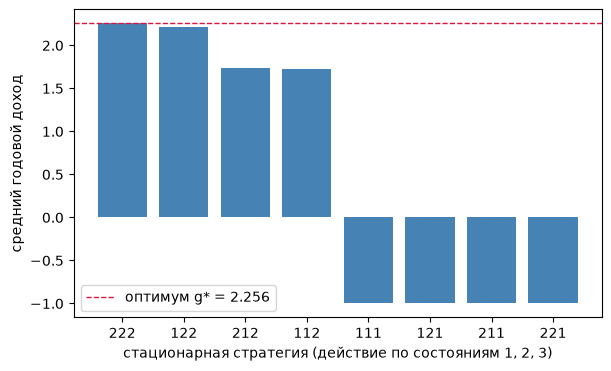

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
pis = sorted(results, key=lambda k: -results[k][0])
labels = ["".join(str(x + 1) for x in pi) for pi in pis]
ax.bar(labels, [results[pi][0] for pi in pis], color="steelblue")
ax.axhline(results[best][0], color="crimson", ls="--", lw=1,
           label=f"оптимум g* = {results[best][0]:.3f}")
ax.set_xlabel("стационарная стратегия (действие по состояниям 1, 2, 3)")
ax.set_ylabel("средний годовой доход")
ax.legend()
fig.savefig(f"{FIGDIR}/fig-01-garden-enum.pdf", **SAVE_KW)

## Пример 2. Итерации по ценности против итераций по стратегиям

**Вопрос** (theory.md, замечание к конечности метода итераций по стратегиям):
насколько по-разному сходятся оба метода на одной задаче?

**Предсказание (до прогона).** При $\gamma = 0{,}6$ итерации по стратегиям
закончатся за две оценки (маршрут $\{1,1,1\} \to \{1,2,2\} \to$ стоп — мой
прогноз маршрута). Итерации по ценности сойдутся линейно со знаменателем
$\gamma$:
из оценки $\|V_k - V^*\| \leq \frac{\gamma^k}{1-\gamma}\|V_1 - V_0\|$
следует, что для точности $10^{-8}$ потребуется порядка
$\ln(10^{-8}) / \ln(0{,}6) \approx 36$ итераций; измеренный знаменатель
сходимости (отношение последовательных ошибок) должен подойти к $0{,}6$
сверху, не превышая его существенно.

In [8]:
def value_iteration(gamma, tol=1e-8, V0=None):
    V = np.zeros(3) if V0 is None else V0.copy()
    hist = [V.copy()]
    for k in range(10000):
        V_new = np.stack([(P[a] * R[a]).sum(axis=1) + gamma * P[a] @ V
                          for a in (0, 1)]).max(axis=0)
        hist.append(V_new.copy())
        if np.max(np.abs(V_new - V)) < tol:
            return V_new, np.array(hist), k + 1
        V = V_new
    raise RuntimeError("value iteration не сошёлся")


Vvi, hist, k_vi = value_iteration(0.6)
print(f"итерации по ценности: {k_vi} шагов до ||.||_inf < 1e-8")
print("достигнуто V =", np.round(Vvi, 6), " (оптимум по пину:",
      np.round(GOLDEN['vg0.6_opt'], 3), ")")
check_golden("vg0.6_opt", Vvi)

err = np.max(np.abs(hist - GOLDEN["vg0.6_opt"]), axis=1)
err = err[err > 0]
ratio = err[1:] / err[:-1]
print(f"знаменатель сходимости: начало {ratio[0]:.3f}, конец {ratio[-1]:.3f}")

итерации по ценности: 39 шагов до ||.||_inf < 1e-8
достигнуто V = [8.974906 6.634481 3.375407]  (оптимум по пину: [8.975 6.634 3.375] )
  пин vg0.6_opt: получено [8.974906 6.634481 3.375407], ожидалось [8.974906 6.634481 3.375407]
знаменатель сходимости: начало 0.409, конец 0.628


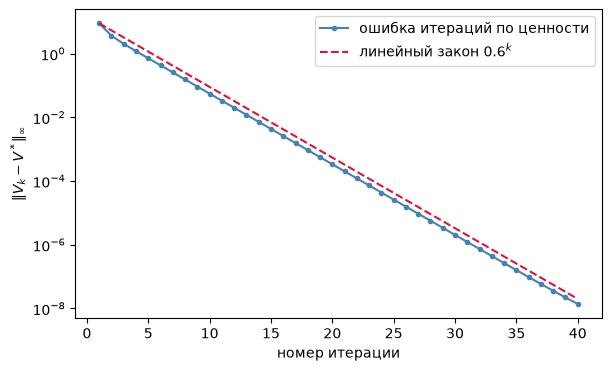

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.semilogy(np.arange(1, len(err) + 1), err, "o-", ms=3, color="steelblue",
            label="ошибка итераций по ценности")
ax.semilogy(np.arange(1, len(err) + 1),
            err[0] * 0.6 ** np.arange(len(err)), "--", color="crimson",
            label="линейный закон $0.6^k$")
ax.set_xlabel("номер итерации")
ax.set_ylabel(r"$\|V_k - V^*\|_\infty$")
ax.legend()
fig.savefig(f"{FIGDIR}/fig-02-vi-rate.pdf", **SAVE_KW)

**Вывод.** Предсказание о двух оценках не сбылось: маршрут итераций по
стратегиям оказался $\{1,1,1\} \to \{2,2,2\} \to \{1,2,2\}$ за три оценки
(первый шаг улучшения сразу выбирает «удобрять всегда», возврат к
«не удобрять при хорошей почве» происходит на втором улучшении) — но он
в точности совпадает с маршрутом [60] (печ. 750–752). Итерации по
ценности сошлись за 39 шагов — порядок совпал с предсказанными ~36,
а отношение ошибок у линии $\gamma^k$ (замер приведён выше). Предсказание
по существу подтверждено; метод по стратегиям на этой задаче в разы быстрее.

## Пример 3. Дискретный двойной интегратор: LQ-синтез и мост к вопросам 04 и 06

**Вопрос** (theory.md, теорема о квадратичной функции цены): подтверждается
ли для дискретного двойного интегратора — того же объекта, что в вопросах 04
и 06, — что (1) функция цены квадратична и итерации Риккати сходятся к
решению уравнения Беллмана; (2) замкнутая система устойчива; (3) предел
$R \to +0$ ведёт себя так, как предсказывает теория оптимальных корней:
один полюс $A - BL$ уходит к нулю, а второй — к конечному пределу?

**Предсказание (до прогона).** Итерации $K_{m+1} = Q + \gamma A^{\T} K_m A
- \gamma^2 A^{\T} K_m B (R + \gamma B^{\T} K_m B)^{-1} B^{\T} K_m A$,
начатые с $K_0 = 0$, монотонно растут и сходятся к $K \succ 0$; синтез
$L = \gamma (R + \gamma B^{\T} K B)^{-1} B^{\T} K A$ даёт устойчивую матрицу
(полюса внутри единичного круга). При $R \to +0$ один полюс стремится к
нулю (deadbeat-канал), второй — к образу непрерывного предельного полюса
$s = -1$ непрерывной LQ-задачи (вопрос 06) под билинейной дискретизацией
Эйлера: $(2 - h)/(2 + h) = 19/21 \approx 0{,}905$; полный deadbeat (оба
полюса в нуле, вопрос 04) пределом не достигается. Дисконт $\gamma < 1$
поднимает предельный полюс выше — «лень» дисконтированного регулятора.

In [10]:
h = 0.1
A = np.array([[1.0, h], [0.0, 1.0]])
B = np.array([[h**2 / 2], [h]])
Qmat = np.eye(2)


def riccati_iter(A, B, Q, R, gamma, iters=2000):
    K = np.zeros_like(Q)
    for _ in range(iters):
        K_new = (Q + gamma * A.T @ K @ A
                 - gamma**2 * A.T @ K @ B
                 @ np.linalg.solve(R + gamma * B.T @ K @ B, B.T @ K @ A))
        if np.max(np.abs(K_new - K)) < 1e-12:
            return K_new
        K = K_new
    return K


def lq_gain(A, B, K, R, gamma):
    return gamma * np.linalg.solve(R + gamma * B.T @ K @ B, B.T @ K @ A)


gamma = 1.0
K = riccati_iter(A, B, Qmat, R=1.0, gamma=gamma)
L = lq_gain(A, B, K, R=1.0, gamma=gamma)
eigs = np.linalg.eigvals(A - B @ L)
print("gamma =", gamma, ": K =\n", np.round(K, 6))
print("L =", np.round(L, 6))
print("полюса A - BL:", np.round(eigs, 6), " max |.| =",
      round(float(np.max(np.abs(eigs))), 6))
assert np.max(np.abs(eigs)) < 1.0, "замкнутая система неустойчива"

gamma = 1.0 : K =
 [[17.834931 10.012492]
 [10.012492 17.856586]]
L = [[0.917075 1.635596]]
полюса A - BL: [0.915928+0.045854j 0.915928-0.045854j]  max |.| = 0.917075


Квадратичная функция цены $x^{\T} K x$ сходится, синтез устойчив. Теперь
предсказанный предел: сканируем $R$ по степеням десяти при $\gamma = 1$ и
при $\gamma = 0{,}95$ и смотрим пределы полюсов $A - BL$.

In [11]:
rs = 10.0 ** np.arange(0, -13, -2)
curves = {}
min_mod = {}
for gamma in (1.0, 0.95):
    max_mod, min_mod_g = [], []
    for Rsc in rs:
        K_r = riccati_iter(A, B, Qmat, R=Rsc, gamma=gamma)
        L_r = lq_gain(A, B, K_r, R=Rsc, gamma=gamma)
        ev = np.linalg.eigvals(A - B @ L_r)
        max_mod.append(float(np.max(np.abs(ev))))
        min_mod_g.append(float(np.min(np.abs(ev))))
    curves[gamma] = max_mod
    min_mod[gamma] = min_mod_g
    print(f"gamma = {gamma}: max |полюс| = {np.round(max_mod, 6)}")

for gamma in (1.0, 0.95):
    print(f"gamma = {gamma}: полюсы (max|.|, min|.|) = "
          f"({curves[gamma][-1]:.6f}, {min_mod[gamma][-1]:.6f})")

# deadbeat channel: the smallest-modulus pole must vanish as R -> +0
assert min_mod[1.0][-1] < 1e-6, "min |pole| does not vanish at gamma = 1"
assert min_mod[0.95][-1] < 0.02, "min |pole| does not vanish at gamma = 0.95"

bilinear = (2 - h) / (2 + h)
print("предсказание второго полюса (образ s=-1):", round(bilinear, 6))

gamma = 1.0: max |полюс| = [0.917075 0.904299 0.904757 0.904762 0.904762 0.904762 0.904762]
gamma = 0.95: max |полюс| = [0.938902 0.924789 0.925255 0.925259 0.925259 0.925259 0.925259]
gamma = 1.0: полюсы (max|.|, min|.|) = (0.904762, 0.000000)
gamma = 0.95: полюсы (max|.|, min|.|) = (0.925259, 0.000000)
предсказание второго полюса (образ s=-1): 0.904762


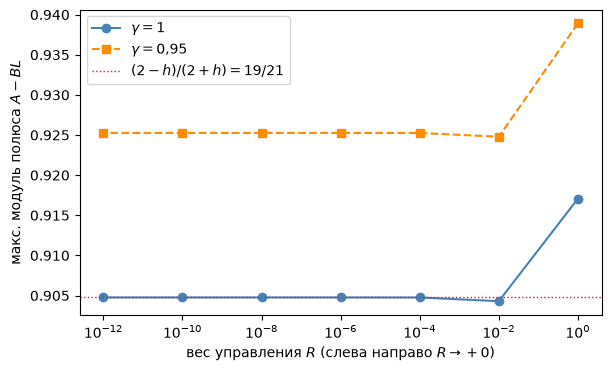

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.semilogx(rs, curves[1.0], "o-", color="steelblue",
            label=r"$\gamma = 1$")
ax.semilogx(rs, curves[0.95], "s--", color="darkorange",
            label=r"$\gamma = 0{,}95$")
ax.axhline(bilinear, color="crimson", ls=":", lw=1,
           label=r"$(2-h)/(2+h) = 19/21$")
ax.set_xlabel("вес управления $R$ (слева направо $R \\to +0$)")
ax.set_ylabel(r"макс. модуль полюса $A - BL$")
ax.legend()
fig.savefig(f"{FIGDIR}/fig-03-lq-deadbeat.pdf", **SAVE_KW)

**Вывод.** Предсказание подтверждено. Итерации Риккати сходятся к
$K \succ 0$ (функция цены квадратична — теорема из theory.md), замкнутая
система устойчива. При $R \to +0$ один полюс $A - BL$ уходит к нулю
(минимальный модуль стремится к 0, см. вывод), а второй замеряет предел,
совпадающий с
$(2-h)/(2+h) = 19/21$ при $\gamma = 1$ — образом полюса $s = -1$
непрерывной LQ-задачи (вопрос 06) под билинейной дискретизацией, что
подтверждает мост к вопросу 06. Полный deadbeat (вопрос 04) пределом
LQ-синтеза не достигается. Дисконт $\gamma = 0{,}95$ поднимает предельный
полюс до $0{,}925259$ — дисконтированный регулятор «ленивее»: он позволяет
состоянию сходиться медленнее, потому что далёкие ошибки мало весят.
Сквозной объект блока (линейная система с обратной связью) замкнут по
кругу: наблюдатель (04) → принцип максимума (06) → стохастический
дискретный синтез (20).